### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf, plot_predict

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [7]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2019-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [8]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [9]:
data.shape

(31972, 14)

In [10]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [11]:
DOFM_Y = data.copy()
mask = (DOFM_Y['category']=='oil and fats') & (DOFM_Y['region']=='Yangon')
DOFM_Y = DOFM_Y[mask]
DOFM_Y.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
1100,1/15/2009,Yangon,Yangon (West),Yangon,oil and fats,Oil (groundnut),groundnut,NaN,1.6 KG,actual,Retail,MMK,3087.34,1.7345
1203,2/15/2009,Yangon,Yangon (West),Yangon,oil and fats,Oil (groundnut),groundnut,NaN,1.6 KG,actual,Retail,MMK,2973.68,1.6706
1314,3/15/2009,Yangon,Yangon (West),Yangon,oil and fats,Oil (groundnut),groundnut,NaN,1.6 KG,actual,Retail,MMK,2910.92,1.6353
1420,4/15/2009,Yangon,Yangon (West),Yangon,oil and fats,Oil (groundnut),groundnut,NaN,1.6 KG,actual,Retail,MMK,2858.37,1.6058
1530,5/15/2009,Yangon,Yangon (West),Yangon,oil and fats,Oil (groundnut),groundnut,NaN,1.6 KG,actual,Retail,MMK,2912.63,1.6363


In [12]:
DOFM_Y = DOFM_Y[['date', 'price']]
DOFM_Y['date'] = pd.to_datetime(DOFM_Y['date'])
mask = (DOFM_Y['date']>=obv_st_date) & (DOFM_Y['date']<=obv_end_date)
DOFM_Y = DOFM_Y.loc[mask]
DOFM_Y = DOFM_Y.set_index('date')
DOFM_Y.head()

,price
date,
2009-01-15,3087.34
2009-02-15,2973.68
2009-03-15,2910.92
2009-04-15,2858.37
2009-05-15,2912.63


In [13]:
DOFM_Y = DOFM_Y.resample('MS').mean()
DOFM_Y.head()

,price
date,
2009-01-01,3087.34
2009-02-01,2973.68
2009-03-01,2910.92
2009-04-01,2858.37
2009-05-01,2912.63


In [14]:
DOFM_Y = DOFM_Y.bfill()
DOFM_Y.shape

(157, 1)

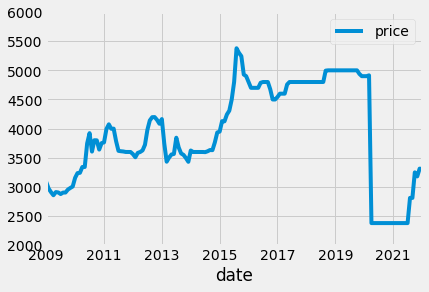

In [15]:
DOFM_Y.plot(grid=True)
plt.show()

It has positive trend.

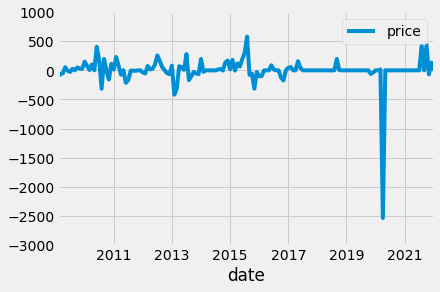

In [16]:
DOFM_Y_diff1 = DOFM_Y.diff(1).dropna()
DOFM_Y_diff1.plot(grid=True)
plt.show()

##### Checking Random Walk

In [17]:
RW_DOFM_Y= adfuller(DOFM_Y_diff1)
RW_DOFM_Y[1] # print P-value. If p-value<5%, reject null hypothesis

6.522323959001659e-22

##### Plotting ACF and PACF

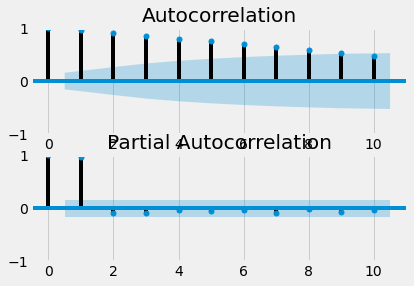

In [18]:
fig, axes=plt.subplots(2,1)
plot_acf(DOFM_Y, lags=10, ax=axes[0])
plot_pacf(DOFM_Y, lags=10, ax=axes[1])
plt.show()

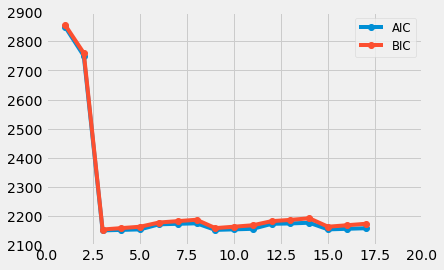

In [19]:
AIC, BIC = AIC_BIC_withOrderRange(DOFM_Y, p=3, d=2, q=3)
# 0:(0,0,0), 1:(0,0,1), 2:(0,0,2), 3:(0,1,0), 4:(0,1,1), 5:(0,1,2), 
# 6:(1,0,0), 7:(1,0,1), 8:(1,0,2), 9:(1,1,0), 10:(1,1,1), 11:(1,1,2), 
# 12:(2,0,0), 13:(2,0,1), 14:(2,0,2), 15:(2,1,0), 16:(2,1,1), 17:(2,1,2)

In [20]:
AIC, BIC

(array([3052.71857636, 2849.96055746, 2749.80636182, 2151.08490333,
        2152.85764338, 2154.57743975, 2171.95603779, 2173.69569641,
        2175.39091652, 2152.84073238, 2154.65653384, 2156.56370707,
        2173.67326958, 2174.94998811, 2177.40165477, 2154.57471501,
        2156.56934188, 2158.54922013]),
 array([3055.77482216, 2856.07304907, 2758.97509923, 2154.13475933,
        2158.95735539, 2163.72700777, 2178.0685294 , 2182.86443382,
        2187.61589975, 2158.94044439, 2163.80610186, 2168.7631311 ,
        2182.842007  , 2187.17497133, 2192.68288379, 2163.72428303,
        2168.76876591, 2173.79850017]))

We will run again 3:(0,1,0), 4:(0,1,1), 5:(0,1,2), 9:(1,1,0), 10:(1,1,1), 11:(1,1,2), 15:(2,1,0), 16:(2,1,1), 17:(2,1,2)

In [21]:
mod_orders = [
    (0,1,0), 
    (0,1,1), 
    (0,1,2), 
    (1,1,0), 
    (1,1,1), 
    (1,1,2), 
    (2,1,0), 
    (2,1,1), 
    (2,1,2)
]

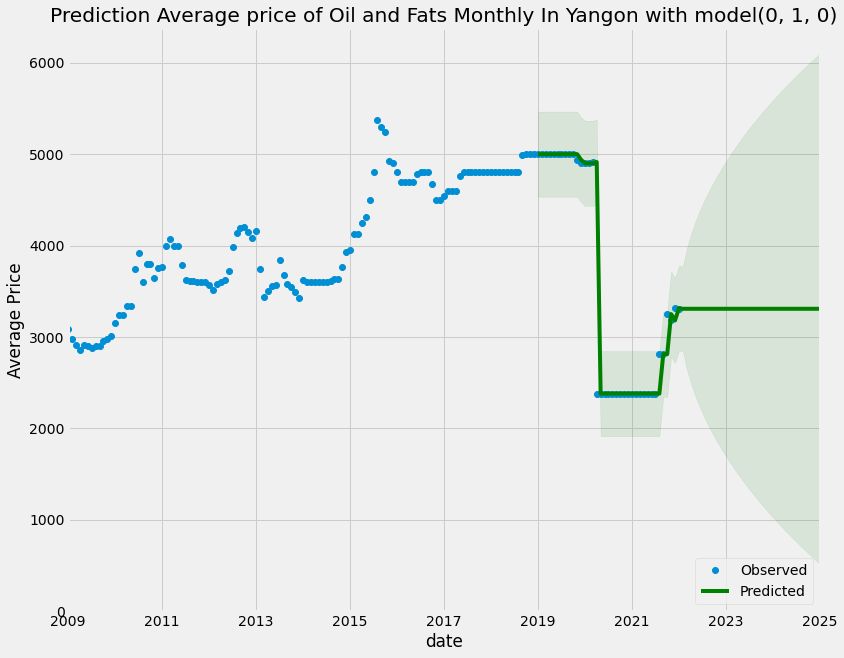

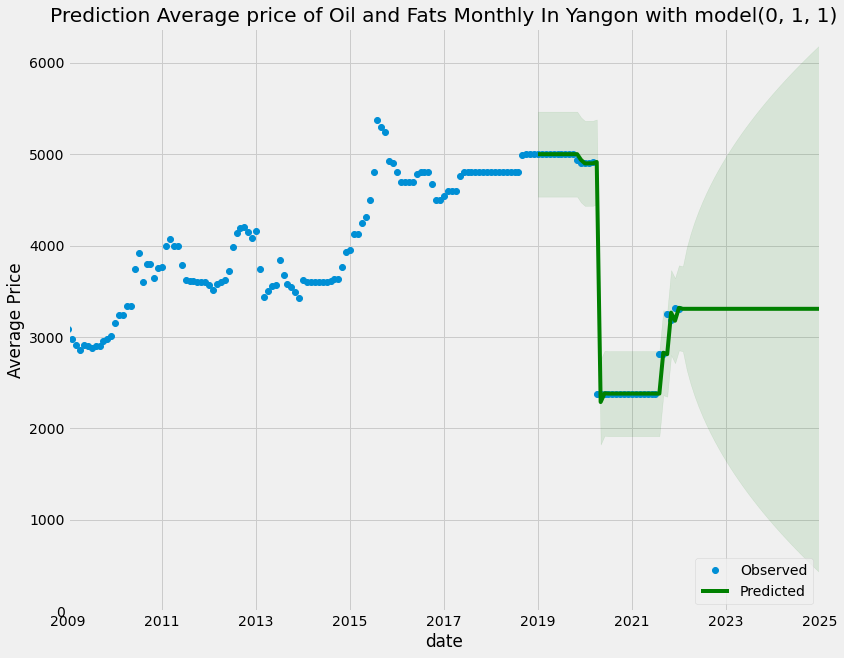

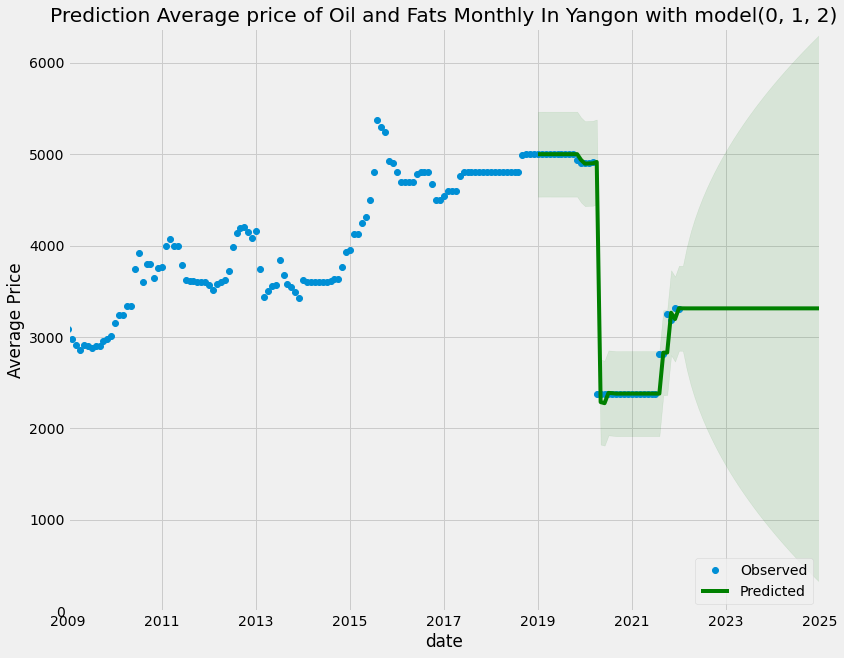

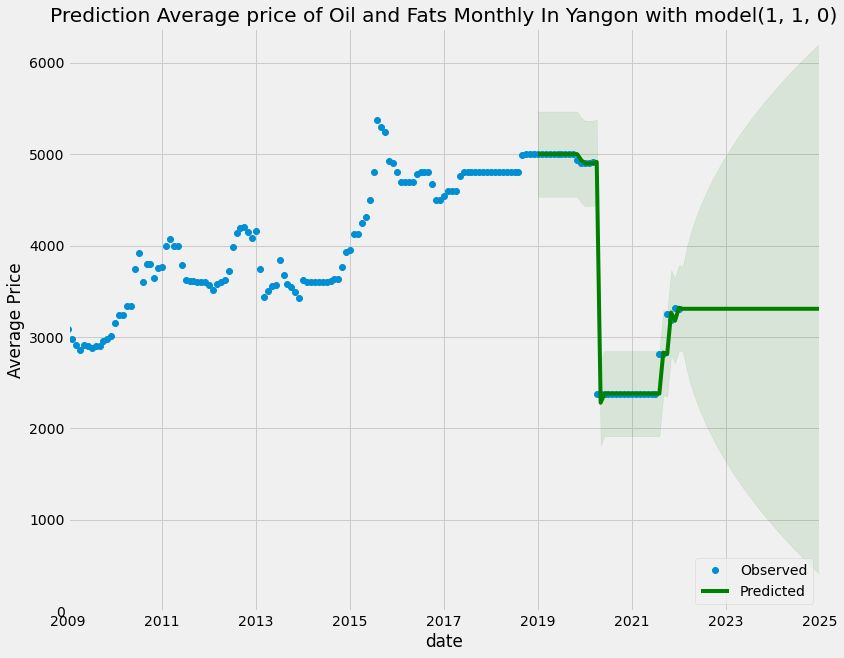

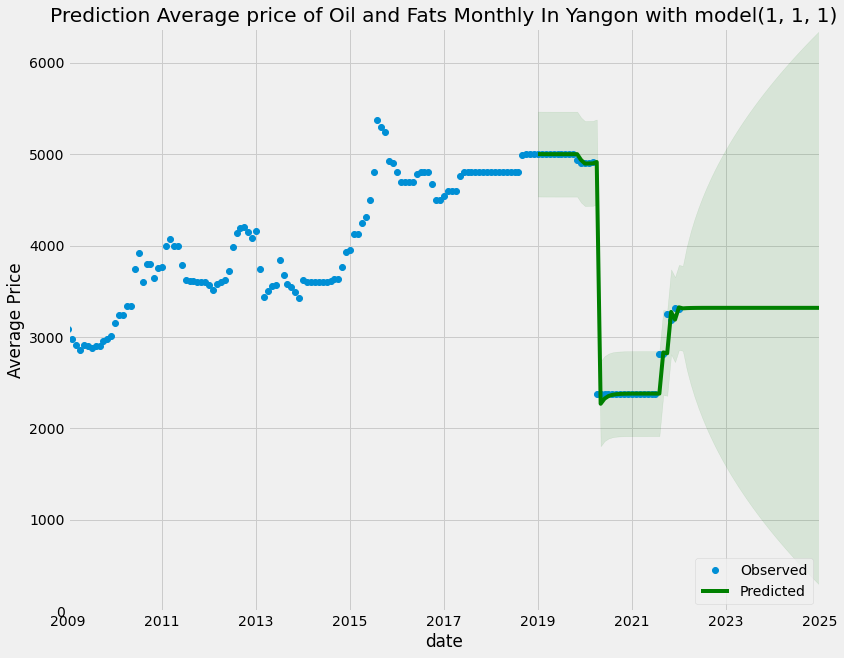

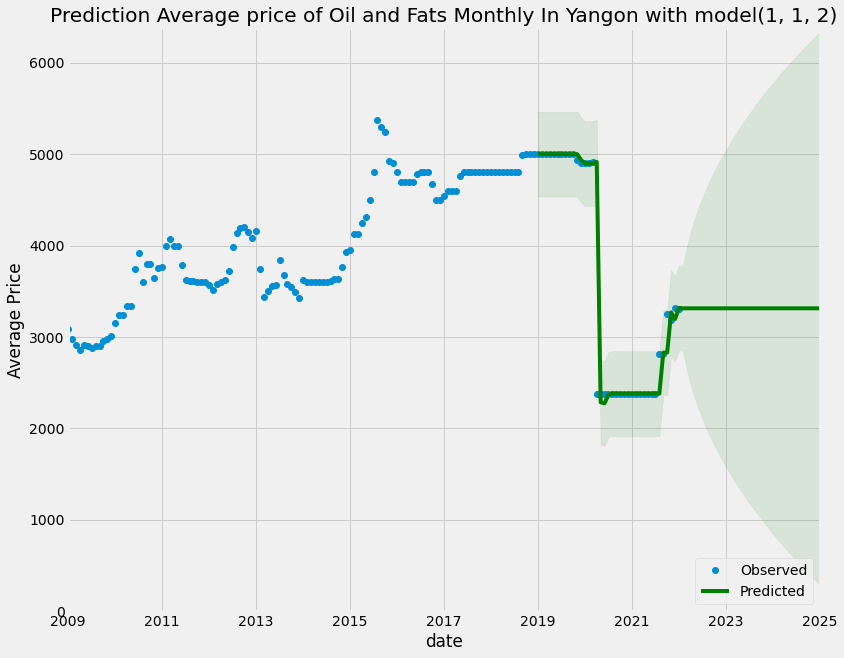

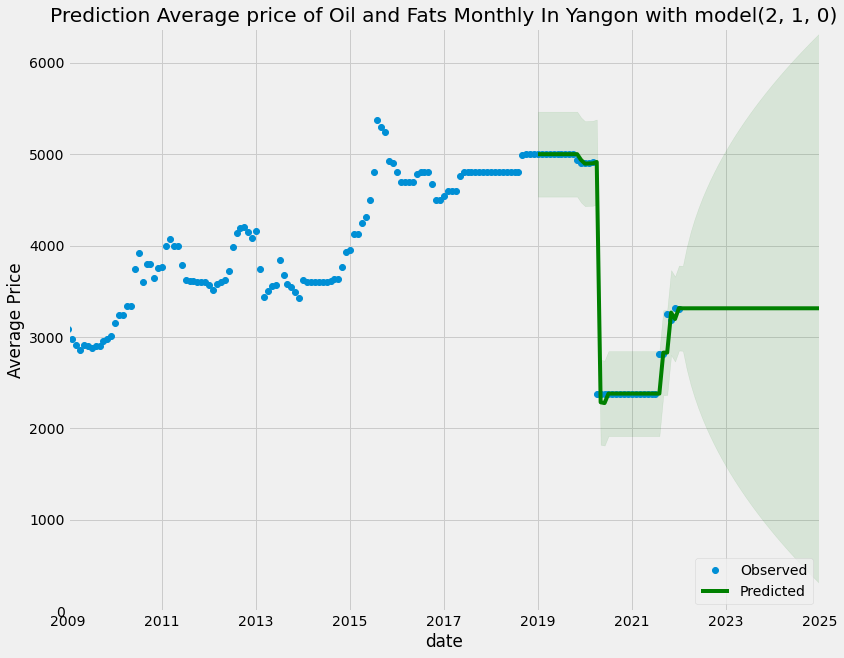

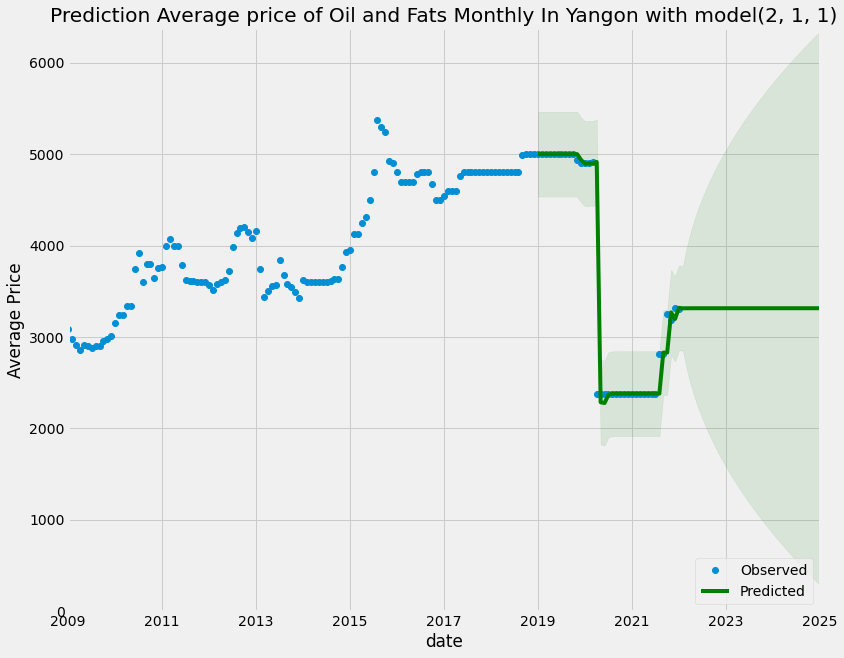

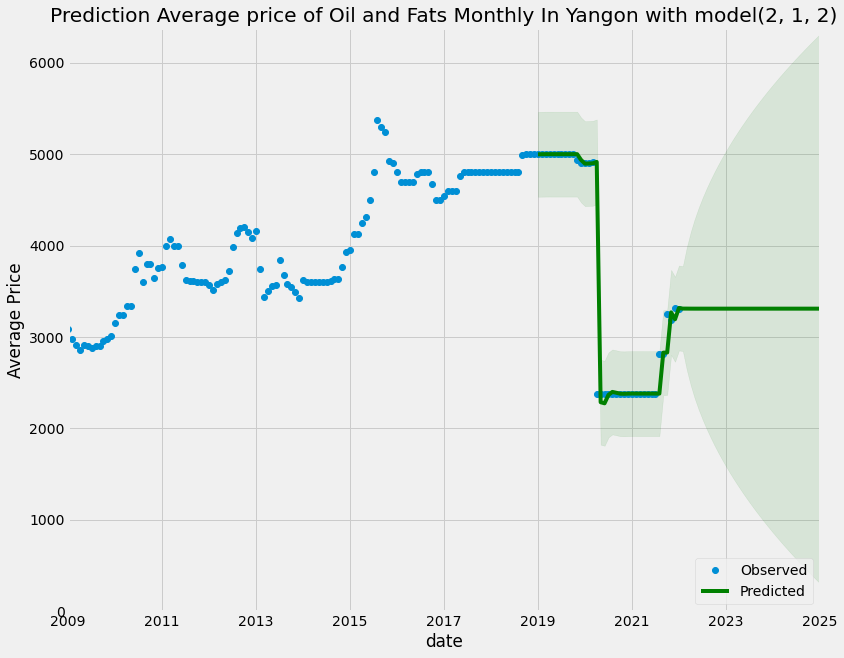

In [22]:
DOFM_Y_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DOFM_Y, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Oil and Fats Monthly In Yangon with model'+str(order), xlabel='Date', ylabel='Average Price')
    DOFM_Y_models.append(model)

Now we choose (0,1,0)

In [23]:
DOFM_Y_model = DOFM_Y_models[0]

In [24]:
DOFM_Y_pred = DOFM_Y_model.predict(pred_st_date, pred_end_date)
DOFM_Y_pred

2019-01-01    5000.0
2019-02-01    5000.0
2019-03-01    5000.0
2019-04-01    5000.0
2019-05-01    5000.0
               ...  
2024-09-01    3308.8
2024-10-01    3308.8
2024-11-01    3308.8
2024-12-01    3308.8
2025-01-01    3308.8
Freq: MS, Name: predicted_mean, Length: 73, dtype: float64